# Avance 4. Modelos alternativos: comparación y elección del modelo final

**Inferencia de propiedades físicas de galaxias a partir de imágenes multibanda** · Instituto Tecnológico y de Estudios Superiores de Monterrey · Maestría en Inteligencia Artificial Aplicada · **Equipo 24** · Colaboración con el Instituto de Astronomía de la UNAM

| Integrante | Matrícula |
|---|---|
| Luz Copelia Minutti Pérez | A01796921 |
| Erick Alberto Bustos Cruz | A01378966 |
| José Florencio Maguey Peralta | A01796727 |

**Asesores:** Dr. Iván Reyes Amezcua (ITESM) · Dr. Héctor Hernández Toledo y Dr. José Antonio Vázquez Mata (IA-UNAM)

**Fase de CRISP-ML(Q):** 3, *Machine Learning Model Engineering* (Studer et al. 2021).

## 1. Objetivo y alcance

Este cuaderno cierra el Avance 4. A lo largo del avance, el equipo construyó, ajustó y analizó varios modelos individuales para estimar la masa estelar (log M\*), la tasa de formación estelar (log SFR) y el índice D4000 de galaxias de MaNGA a partir de sus imágenes de DESI en las bandas g, r y z. Cada modelo tiene su propio cuaderno en esta carpeta. Aquí reunimos sus resultados para responder la pregunta central del avance: qué algoritmo describe mejor la relación entre la imagen de una galaxia y sus propiedades físicas, y cuál conviene llevar a la siguiente etapa del proyecto.

El recorrido sigue ese orden. Primero comparamos todos los modelos con las mismas reglas (sección 3) y, con esa comparación, seleccionamos los dos mejores (sección 4). Después revisamos cómo ajustamos cada uno y cuánto mejoró (sección 5) y elegimos el modelo final a partir de todas sus métricas (sección 6). Como los números provienen de las salidas ya ejecutadas de cada cuaderno, y cada uno lleva su fuente, este cuaderno se ejecuta en segundos y sin GPU.

| Modelo | Algoritmo | Cuaderno |
|---|---|---|
| 1 | Red convolucional ResNet50 multitarea, ajustada con las imágenes (siete variantes de diseño, A a G) | `Modelo_1_ResNet50_multitarea_con_RGB_GRZ_redshift_Huber.ipynb` |
| 2 | Máquina de vectores de soporte para regresión (SVR) sobre características de ResNet50 preentrenada | `DESI_Modelo_2_SVR_Imagenes_Redshift._m2.ipynb` |
| 3 | Red convolucional moderna ConvNeXt-Tiny, ajustada con las imágenes | `Modelo3_ConvNeXt_Tiny_imagen.ipynb` |
| 4 | Transformador de visión DINOv3 ViT-L, modelo fundacional autosupervisado, ajustado con LoRA | `Modelo4_DINOv3_imagen.ipynb` |
| 5 | Regresión lineal Ridge sobre las mismas características del SVR | `Modelos_5_6_Ridge_KNN.ipynb` |
| 6 | Regresión por vecinos más cercanos (KNN, 15 vecinos) sobre las mismas características del SVR | `Modelos_5_6_Ridge_KNN.ipynb` |

Los seis modelos cubren familias de algoritmos distintas: dos redes convolucionales ajustadas con las imágenes, una de diseño clásico y otra moderna; un transformador de visión fundacional, y tres modelos clásicos de aprendizaje automático (de kernel, lineal y de vecinos más cercanos) sobre un mismo conjunto de características preentrenadas. Esta última elección permite comparar los tres algoritmos clásicos con exactamente las mismas entradas.

## 2. Reglas de la comparación

Para que las diferencias entre modelos se deban al algoritmo y no a los datos, todos siguen el protocolo común del equipo. Usan las mismas 9,299 galaxias de MaNGA con imagen de DESI válida, divididas en 7,121 de entrenamiento, 1,261 de validación y 917 de prueba, y las mismas etiquetas del catálogo Pipe3D: log M\* y log SFR, en dex, y D4000. Cualquier parámetro que dependa de los datos, como las escalas de la imagen o las medias y desviaciones, lo calculamos solo con las galaxias de entrenamiento.

La métrica principal es el **MSE normalizado medio**. Para cada propiedad dividimos el error cuadrático medio entre la varianza de esa propiedad en entrenamiento, (RMSE / σ_entrenamiento)², y promediamos el resultado de las tres propiedades. Normalizar permite promediar propiedades con unidades distintas: un valor de 0 corresponde a predicciones perfectas y uno de 1 a predecir siempre la media, así que menor es mejor. Como una sola cifra puede esconder diferencias importantes entre propiedades, reportamos también el RMSE, el MAE y el R² de cada una en su escala original.

Tomamos todas las decisiones con el conjunto de validación y reservamos el conjunto de prueba para evaluar una sola vez cada modelo elegido. Entrenamos los modelos basados en redes con las semillas 42, 7 y 2026. En ConvNeXt-Tiny y DINOv3 reportamos la media de las tres semillas; la ResNet50 se representa, como en su cuaderno, con la red de la semilla 42, y la desviación entre sus tres semillas indica su estabilidad. El SVR, Ridge y KNN son deterministas y tienen una sola corrida.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

PROPIEDADES = ("M*", "SFR", "D4000")
COLOR_MODELO = {1: "#8d99ae", 2: "#bc6c25", 3: "#2a9d8f", 4: "#264653", 5: "#e9c46a", 6: "#9b5de5"}

## 3. Comparación de los modelos

Con estas reglas, la tabla reúne la mejor versión de cada modelo, tal como la eligió su cuaderno con el conjunto de validación. La columna «resultado» indica si cada valor corresponde a una sola red o a la media de tres semillas; los valores coinciden con la tabla de los seis modelos del cuaderno de los modelos 5 y 6. Los tiempos de entrenamiento son por entrenamiento completo de una semilla y dependen de la GPU con que los medimos, que indicamos en la tabla.

In [2]:
# Resultados en validación (1,261 galaxias) de la mejor versión de cada modelo.
# Fuente: las salidas ejecutadas de cada cuaderno (columna "fuente"); los valores coinciden con la tabla
# de los seis modelos del cuaderno de los modelos 5 y 6 (sección 9).
MODELOS = [
    dict(numero=1, modelo="ResNet50 multitarea (variante E)", familia="red convolucional ajustada",
         mse=0.127879, mse_sd=0.001525, semillas=1, resultado="individual (semilla 42)",
         rmse=(0.108829, 0.597520, 0.073037), mae=(0.082898, 0.394586, 0.052342), r2=(0.972454, 0.736249, 0.903949),
         minutos_entrenamiento=np.nan, gpu="RTX A4000", parametros_M=25.08, ms_inferencia=np.nan,
         entradas="imagen GRZ + redshift", fuente="Modelo 1, sección 12"),
    dict(numero=2, modelo="SVR sobre características de ResNet50", familia="kernel (SVR)",
         mse=0.442091, mse_sd=np.nan, semillas=1, resultado="individual",
         rmse=(0.2661, 0.9828, 0.1611), mae=(0.1995, 0.7599, 0.1259), r2=(0.8353, 0.2865, 0.5326),
         minutos_entrenamiento=(6.02 + 8.01 + 7.76) / 60, gpu="CPU (solo el ajuste del SVR)", parametros_M=np.nan, ms_inferencia=np.nan,
         entradas="imagen + redshift", fuente="Modelo 2, secciones 5 y 6"),
    dict(numero=3, modelo="ConvNeXt-Tiny ajustado", familia="red convolucional ajustada",
         mse=0.1625, mse_sd=0.0031, semillas=3, resultado="media de 3 semillas",
         rmse=(0.2281, 0.6069, 0.0728), mae=(0.1742, 0.4315, 0.0516), r2=(0.8789, 0.7279, 0.9045),
         minutos_entrenamiento=5.99, gpu="A100", parametros_M=28.41, ms_inferencia=0.45,
         entradas="imagen GRZ", fuente="Modelo 3, sección 12"),
    dict(numero=4, modelo="DINOv3 ViT-L con LoRA", familia="transformador de visión fundacional",
         mse=0.1522, mse_sd=0.0017, semillas=3, resultado="media de 3 semillas",
         rmse=(0.2213, 0.5871, 0.0702), mae=(0.1698, 0.4112, 0.0486), r2=(0.8861, 0.7453, 0.9112),
         minutos_entrenamiento=24.09, gpu="A100", parametros_M=308.19, ms_inferencia=2.71,
         entradas="imagen en color (Lupton)", fuente="Modelo 4, sección 13"),
    dict(numero=5, modelo="Regresión Ridge sobre características de ResNet50", familia="lineal regularizado",
         mse=0.387151, mse_sd=np.nan, semillas=1, resultado="individual",
         rmse=(0.241779, 0.916069, 0.153374), mae=(0.189112, 0.711237, 0.120821), r2=(0.8640, 0.3801, 0.5764),
         minutos_entrenamiento=np.nan, gpu="CPU", parametros_M=390 / 1e6, ms_inferencia=np.nan,
         entradas="imagen + redshift", fuente="Modelos 5 y 6, sección 9"),
    dict(numero=6, modelo="KNN sobre características de ResNet50", familia="vecinos más cercanos (no paramétrico)",
         mse=0.627998, mse_sd=np.nan, semillas=1, resultado="individual",
         rmse=(0.426436, 1.083441, 0.184621), mae=(0.350682, 0.893574, 0.153836), r2=(0.5771, 0.1328, 0.3863),
         minutos_entrenamiento=np.nan, gpu="CPU", parametros_M=np.nan, ms_inferencia=np.nan,
         entradas="imagen + redshift", fuente="Modelos 5 y 6, sección 9"),
]

filas = []
for m in MODELOS:
    fila = {"modelo": f"{m['numero']} · {m['modelo']}", "familia": m["familia"], "resultado": m["resultado"],
            "MSE normalizado medio": m["mse"], "desviación entre semillas": m["mse_sd"]}
    for nombre, valores in (("RMSE", m["rmse"]), ("MAE", m["mae"]), ("R²", m["r2"])):
        for propiedad, valor in zip(PROPIEDADES, valores):
            fila[f"{nombre} {propiedad}"] = valor
    fila.update({"min por entrenamiento": m["minutos_entrenamiento"], "GPU": m["gpu"],
                 "parámetros (M)": m["parametros_M"], "ms por galaxia": m["ms_inferencia"],
                 "entradas": m["entradas"], "fuente": m["fuente"]})
    filas.append(fila)
COMPARATIVA = (pd.DataFrame(filas).sort_values("MSE normalizado medio").reset_index(drop=True))
COMPARATIVA.index = COMPARATIVA.index + 1
COMPARATIVA.index.name = "lugar"
TABLA = COMPARATIVA.copy()
TABLA["min por entrenamiento"] = TABLA["min por entrenamiento"].round(1)
TABLA["parámetros (M)"] = TABLA["parámetros (M)"].round(4)
TABLA["desviación entre semillas"] = TABLA["desviación entre semillas"].round(4).astype(object).where(TABLA["desviación entre semillas"].notna(), "una sola corrida")
TABLA = TABLA.round(4).fillna("no reportado")
TABLA["modelo"] = TABLA["modelo"].str.replace(" sobre características de ResNet50", "", regex=False)
METRICAS_VALIDACION = TABLA[["modelo", "resultado", "MSE normalizado medio", "desviación entre semillas"]
                            + [f"{n} {p}" for n in ("RMSE", "MAE", "R²") for p in PROPIEDADES]]
COSTO_Y_FUENTE = TABLA[["modelo", "familia", "entradas", "min por entrenamiento", "GPU", "parámetros (M)", "ms por galaxia", "fuente"]]
print("Métricas en validación, ordenadas por la métrica principal")
display(METRICAS_VALIDACION)
print("Familia, entradas, costo y fuente de cada modelo")
display(COSTO_Y_FUENTE)

Métricas en validación, ordenadas por la métrica principal


,modelo,resultado,MSE normalizado medio,desviación entre semillas,RMSE M*,RMSE SFR,RMSE D4000,MAE M*,MAE SFR,MAE D4000,R² M*,R² SFR,R² D4000
lugar,,,,,,,,,,,,,
1,1 · ResNet50 multitarea (variante E),individual (semilla 42),0.1279,0.0015,0.1088,0.5975,0.0730,0.0829,0.3946,0.0523,0.9725,0.7362,0.9039
2,4 · DINOv3 ViT-L con LoRA,media de 3 semillas,0.1522,0.0017,0.2213,0.5871,0.0702,0.1698,0.4112,0.0486,0.8861,0.7453,0.9112
3,3 · ConvNeXt-Tiny ajustado,media de 3 semillas,0.1625,0.0031,0.2281,0.6069,0.0728,0.1742,0.4315,0.0516,0.8789,0.7279,0.9045
4,5 · Regresión Ridge,individual,0.3872,una sola corrida,0.2418,0.9161,0.1534,0.1891,0.7112,0.1208,0.8640,0.3801,0.5764
5,2 · SVR,individual,0.4421,una sola corrida,0.2661,0.9828,0.1611,0.1995,0.7599,0.1259,0.8353,0.2865,0.5326
6,6 · KNN,individual,0.6280,una sola corrida,0.4264,1.0834,0.1846,0.3507,0.8936,0.1538,0.5771,0.1328,0.3863


Familia, entradas, costo y fuente de cada modelo


,modelo,familia,entradas,min por entrenamiento,GPU,parámetros (M),ms por galaxia,fuente
lugar,,,,,,,,
1,1 · ResNet50 multitarea (variante E),red convolucional ajustada,imagen GRZ + redshift,no reportado,RTX A4000,25.08,no reportado,"Modelo 1, sección 12"
2,4 · DINOv3 ViT-L con LoRA,transformador de visión fundacional,imagen en color (Lupton),24.1,A100,308.19,2.71,"Modelo 4, sección 13"
3,3 · ConvNeXt-Tiny ajustado,red convolucional ajustada,imagen GRZ,6.0,A100,28.41,0.45,"Modelo 3, sección 12"
4,5 · Regresión Ridge,lineal regularizado,imagen + redshift,no reportado,CPU,0.0004,no reportado,"Modelos 5 y 6, sección 9"
5,2 · SVR,kernel (SVR),imagen + redshift,0.4,CPU (solo el ajuste del SVR),no reportado,no reportado,"Modelo 2, secciones 5 y 6"
6,6 · KNN,vecinos más cercanos (no paramétrico),imagen + redshift,no reportado,CPU,no reportado,no reportado,"Modelos 5 y 6, sección 9"


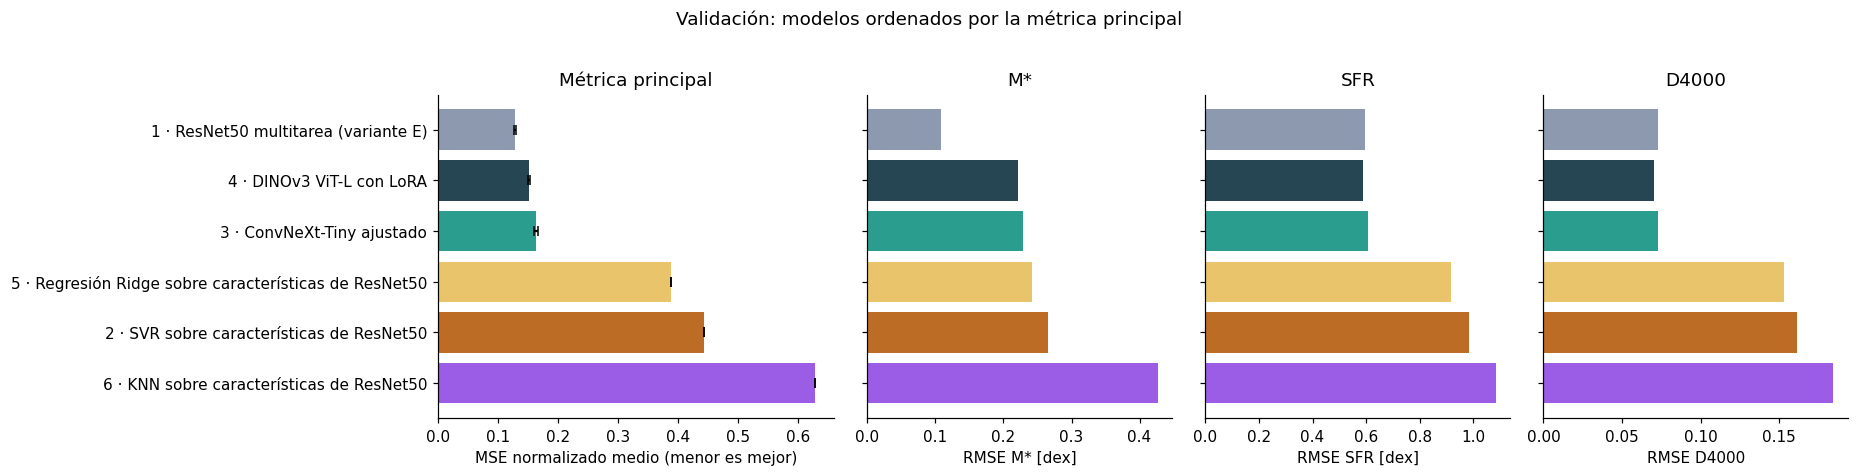

In [3]:
numeros = [int(s.split(" · ")[0]) for s in COMPARATIVA.modelo]
colores = [COLOR_MODELO.get(n, "0.5") for n in numeros]
fig, ejes = plt.subplots(1, 4, figsize=(17, 0.9 + 0.55 * len(COMPARATIVA)), sharey=True,
                         gridspec_kw={"width_ratios": [1.3, 1, 1, 1]})
y = np.arange(len(COMPARATIVA))[::-1]
ejes[0].barh(y, COMPARATIVA["MSE normalizado medio"], xerr=COMPARATIVA["desviación entre semillas"].fillna(0),
             color=colores, capsize=3)
ejes[0].set(yticks=y, yticklabels=COMPARATIVA.modelo, xlabel="MSE normalizado medio (menor es mejor)",
            title="Métrica principal")
for eje, propiedad, unidad in zip(ejes[1:], PROPIEDADES, (" [dex]", " [dex]", "")):
    eje.barh(y, COMPARATIVA[f"RMSE {propiedad}"], color=colores)
    eje.set(xlabel=f"RMSE {propiedad}{unidad}", title=propiedad)
plt.suptitle("Validación: modelos ordenados por la métrica principal", y=1.02)
plt.tight_layout(); plt.show()

Con las mismas reglas, el orden es claro. La ResNet50 multitarea en su variante E (modelo 1) obtiene el menor MSE normalizado medio (0.128), seguida de DINOv3 ViT-L con LoRA (modelo 4, 0.152) y de ConvNeXt-Tiny ajustado (modelo 3, 0.163). Los tres modelos clásicos quedan muy por detrás: Ridge (modelo 5, 0.387), el SVR (modelo 2, 0.442) y KNN (modelo 6, 0.628). Los tres usan las mismas características, las de ResNet50 preentrenada con ImageNet y sin ajustar a las galaxias, más el redshift, así que su diferencia con las redes ajustadas mide cuánto aporta adaptar la representación de la imagen al problema. Entre ellos, la regresión lineal de Ridge supera al SVR, lo que indica que la flexibilidad del kernel no compensa con estas características, y KNN es el peor: en un espacio de 129 dimensiones la distancia entre galaxias distingue mal a las que son físicamente parecidas. Su ajuste perfecto en entrenamiento, que desaparece al excluir a cada galaxia de sus propios vecinos, lo confirma. Los tres estiman razonablemente la masa (R² de 0.58 a 0.86), que depende sobre todo del brillo y del redshift, pero fallan en la SFR (R² de 0.13 a 0.38) y en D4000 (R² de 0.39 a 0.58), que requieren leer el color y la estructura de la galaxia.

La gráfica por propiedad muestra que el orden no es el mismo en las tres. La ventaja del modelo 1 está casi toda en la masa: su RMSE de 0.109 dex es la mitad del de los demás. En la SFR y en D4000, en cambio, el mejor es DINOv3 (0.587 dex y 0.070); en la SFR le sigue el modelo 1 (0.598 dex) y en D4000 los modelos 3 y 1 quedan empatados (0.073). La diferencia en la masa tiene una explicación física: el modelo 1 recibe además el redshift medido con el espectro, que fija la distancia de la galaxia, y la masa depende de la luminosidad, que no se puede calcular sin la distancia.

Los tiempos de entrenamiento van de segundos en el SVR a 24 minutos por semilla en DINOv3. El tiempo del modelo 1 no quedó registrado en su cuaderno, porque recuperamos sus entrenamientos de corridas anteriores, y lo mismo ocurre con Ridge y KNN, que se recuperaron ya ajustados; del SVR solo registramos el tiempo de su ajuste, sin la extracción de características.

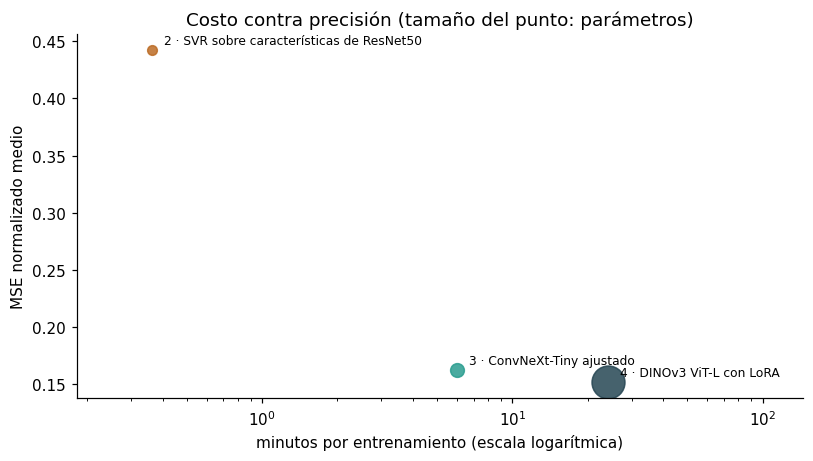

In [4]:
fig, eje = plt.subplots(figsize=(7.5, 4.3))
con_tiempo = COMPARATIVA.dropna(subset=["min por entrenamiento"])
for _, r in con_tiempo.iterrows():
    n = int(r.modelo.split(" · ")[0])
    tam = 40 if np.isnan(r["parámetros (M)"]) else 30 + 2.5 * r["parámetros (M)"] ** 0.9
    eje.scatter(r["min por entrenamiento"], r["MSE normalizado medio"], s=tam, color=COLOR_MODELO.get(n, "0.5"), alpha=0.85)
    eje.annotate(r.modelo, (r["min por entrenamiento"], r["MSE normalizado medio"]), textcoords="offset points",
                 xytext=(8, 4), fontsize=8)
eje.set_xlim(con_tiempo["min por entrenamiento"].min() / 2, con_tiempo["min por entrenamiento"].max() * 6)
eje.set(xscale="log", xlabel="minutos por entrenamiento (escala logarítmica)", ylabel="MSE normalizado medio",
        title="Costo contra precisión (tamaño del punto: parámetros)")
plt.tight_layout(); plt.show()

La gráfica de costo contra precisión resume el compromiso entre los modelos con tiempo registrado. DINOv3 es el más preciso de ellos, pero cuesta cuatro veces más entrenarlo que ConvNeXt (24 contra 6 minutos por semilla en una A100), tiene once veces más parámetros en total (308 M contra 28 M, aunque con LoRA solo se entrenan 5.1 M) y tarda seis veces más en predecir (2.7 contra 0.45 ms por galaxia). El SVR es el más barato con diferencia, pero su error es casi el triple.

## 4. Selección de los dos mejores modelos

Por la métrica principal en validación, los dos mejores modelos son la **ResNet50 multitarea (modelo 1)** y **DINOv3 ViT-L con LoRA (modelo 4)**. ConvNeXt-Tiny (modelo 3) queda en tercer lugar, a 0.010 de DINOv3; como también lo ajustamos a fondo, lo conservamos en el análisis del ajuste fino como referencia de una red convolucional moderna.

In [5]:
DOS_MEJORES = COMPARATIVA.head(2)[["modelo", "MSE normalizado medio", "desviación entre semillas", "RMSE M*", "RMSE SFR", "RMSE D4000"]]
display(DOS_MEJORES.round(4))

,modelo,MSE normalizado medio,desviación entre semillas,RMSE M*,RMSE SFR,RMSE D4000
lugar,,,,,,
1,1 · ResNet50 multitarea (variante E),0.1279,0.0015,0.1088,0.5975,0.0730
2,4 · DINOv3 ViT-L con LoRA,0.1522,0.0017,0.2213,0.5871,0.0702


## 5. Ajuste fino de los mejores modelos

Seleccionar los mejores modelos solo tiene sentido si cada uno llegó a la comparación en su mejor configuración. Ajustamos cada modelo en su cuaderno con una estrategia adecuada a su costo. La tabla resume, para cada uno, el punto de partida, el espacio explorado, el número de experimentos y el resultado, siempre con el criterio de validación. Para comparar el antes y el después con la misma base, en esta sección todos los valores son la media de las tres semillas; por eso la ResNet50 aparece con 0.127 y no con el 0.128 de su red de la semilla 42.

| Modelo | Punto de partida | Qué ajustamos | Experimentos | Método |
|---|---|---|---|---|
| 1 · ResNet50 | Variante A: una red por propiedad, imagen RGB, pérdida MSE | Arquitectura (redes separadas o una red multitarea), representación de la imagen (RGB o bandas GRZ), entradas (con o sin redshift) y pérdida (MSE o Huber) | 7 variantes × 3 semillas = 21 corridas (27 redes) | Diseño de experimentos con contrastes pareados entre variantes |
| 4 · DINOv3 | ViT congelado con una cabeza | Tamaño del modelo (ViT-S, B, L y L satelital), presentación de la imagen, resumen de los tokens, resolución, variante de entrada; hiperparámetros de la cabeza; estrategia de ajuste fino (últimos bloques o LoRA), rango de LoRA, bloques abiertos, tasas de aprendizaje, *weight decay*, decaimiento por capa, *stochastic depth* | 48 combinaciones congeladas, 2 resoluciones, 40 pruebas de la cabeza y 16 de ajuste fino; finalista con 3 semillas | Barrido completo de las representaciones congeladas y Optuna (TPE con poda por *successive halving*) |
| 3 · ConvNeXt-Tiny | Pesos de ImageNet-22k, tasa 10⁻⁴, Huber | Pesos preentrenados (ImageNet-1k, ImageNet-22k o destilados de DINOv3), variante de entrada, tasa del extractor y de la cabeza, *weight decay*, decaimiento por capa, *drop path*, pérdida y calentamiento | 6 corridas base, 30 pruebas de Optuna, 3 finalistas con todas las épocas y el ganador con 3 semillas | Optuna (TPE con poda por *successive halving*) |

,modelo,antes,criterio_antes,sd_antes,despues,criterio_despues,sd_despues,reducción del criterio
0,1 · ResNet50,variante A (inicial),0.1838,0.0019,variante E,0.1269,0.0015,31 %
1,4 · DINOv3,ViT-L congelado con la mejor cabeza,0.2590,0.0024,ViT-L con LoRA de rango 32,0.1522,0.0017,41 %
2,3 · ConvNeXt-Tiny,configuración de partida,0.1769,0.0019,configuración de Optuna,0.1625,0.0031,8 %


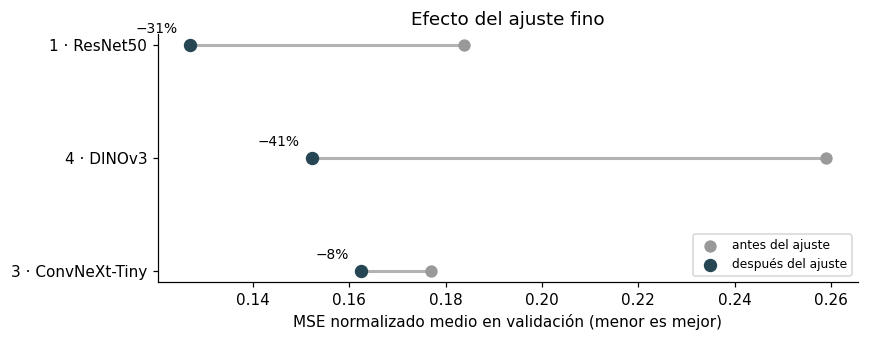

In [6]:
AJUSTE = pd.DataFrame([
    dict(modelo="1 · ResNet50", antes="variante A (inicial)", criterio_antes=0.183782, sd_antes=0.001921,
         despues="variante E", criterio_despues=0.126881, sd_despues=0.001525),
    dict(modelo="4 · DINOv3", antes="ViT-L congelado con la mejor cabeza", criterio_antes=0.2590, sd_antes=0.0024,
         despues="ViT-L con LoRA de rango 32", criterio_despues=0.1522, sd_despues=0.0017),
    dict(modelo="3 · ConvNeXt-Tiny", antes="configuración de partida", criterio_antes=0.1769, sd_antes=0.0019,
         despues="configuración de Optuna", criterio_despues=0.1625, sd_despues=0.0031),
])
AJUSTE["reducción del criterio"] = 1 - AJUSTE.criterio_despues / AJUSTE.criterio_antes
TABLA_AJUSTE = AJUSTE.round(4)
TABLA_AJUSTE["reducción del criterio"] = (AJUSTE["reducción del criterio"] * 100).round(0).astype(int).astype(str) + " %"
display(TABLA_AJUSTE)

fig, eje = plt.subplots(figsize=(8, 3.2))
for k, r in AJUSTE.iterrows():
    eje.plot([r.criterio_antes, r.criterio_despues], [k, k], color="0.7", lw=2, zorder=1)
    eje.scatter(r.criterio_antes, k, color="0.6", s=50, zorder=2, label="antes del ajuste" if k == 0 else None)
    eje.scatter(r.criterio_despues, k, color="#264653", s=60, zorder=3, label="después del ajuste" if k == 0 else None)
    eje.annotate(f"−{r['reducción del criterio']:.0%}", (r.criterio_despues, k), textcoords="offset points", xytext=(-8, 8),
                 ha="right", fontsize=9)
eje.set(yticks=range(len(AJUSTE)), yticklabels=AJUSTE.modelo, xlabel="MSE normalizado medio en validación (menor es mejor)",
        title="Efecto del ajuste fino")
eje.invert_yaxis(); eje.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()

El ajuste fino mejoró a los tres modelos, con distinta profundidad. En la **ResNet50**, el ajuste fue de diseño. Las siete variantes A a G cambian una decisión a la vez, y los contrastes entre ellas, con tres semillas, muestran qué aporta cada una: compartir el extractor entre las tres propiedades (de A a B) casi no cambia el error, usar las bandas GRZ en lugar de RGB mejora un poco, y agregar el redshift reduce el criterio de 0.178 a 0.129 (de F a D), sobre todo por la masa. La pérdida de Huber da la última mejora pequeña (de D a E). En total, la media del criterio entre las tres semillas baja 31 %, de 0.184 a 0.127. Esta exploración no incluyó una búsqueda de la tasa de aprendizaje ni del *weight decay*, que quedaron fijos, así que es posible que la variante E todavía pueda mejorar con una búsqueda como la de los modelos 3 y 4.

En **DINOv3**, el ajuste se hizo en dos niveles. Primero, un barrido completo de las representaciones congeladas mostró que la imagen en color de Lupton, un modelo de al menos el tamaño de ViT-B y el token CLS son la mejor base, y 40 pruebas de Optuna ajustaron la cabeza. Después, la búsqueda de ajuste fino encontró que LoRA de rango 32 con una tasa de unos 2 × 10⁻⁴ supera a abrir los últimos bloques. El criterio baja 41 %, de 0.259 a 0.152. Esta búsqueda fue la más corta en número de pruebas completas (3 de 16, por la poda y el costo de ViT-L), así que su resultado debe tomarse como una buena configuración y no necesariamente como la óptima.

En **ConvNeXt-Tiny**, 30 pruebas de Optuna sobre nueve hiperparámetros redujeron el criterio 8 %, de 0.177 a 0.163. El hiperparámetro más importante fue el decaimiento de la tasa por capa (importancia fANOVA de 0.58): las mejores configuraciones dejan que todas las capas se adapten casi por igual, lo que indica que las imágenes de galaxias son lo bastante distintas de ImageNet como para que también las primeras capas tengan que cambiar.

## 6. Elección del modelo individual final

El ajuste fino deja a los dos mejores modelos, la ResNet50 multitarea (variante E) y DINOv3 ViT-L con LoRA, en su mejor versión. Para elegir entre ellos, la tabla compara a todos los modelos en cada métrica de validación y en los demás aspectos medidos, en el mismo orden de la sección 3.

In [7]:
ASPECTOS = {"resultado": "tipo de resultado", "MSE normalizado medio": "MSE normalizado medio (validación)", "desviación entre semillas": "desviación del criterio entre semillas",
            **{f"{m} {p}": f"{m} de {p}" for m in ("RMSE", "MAE", "R²") for p in PROPIEDADES},
            "parámetros (M)": "parámetros totales (M)", "min por entrenamiento": "minutos por entrenamiento",
            "GPU": "hardware del entrenamiento", "ms por galaxia": "ms de inferencia por galaxia"}
ELECCION = COMPARATIVA.set_index("modelo")[list(ASPECTOS)].rename(columns=ASPECTOS).T
for fila in ELECCION.index:
    if fila not in ("hardware del entrenamiento", "tipo de resultado"):
        vacio = "una sola corrida" if fila == "desviación del criterio entre semillas" else "no reportado"
        ELECCION.loc[fila] = [round(float(v), 4) if pd.notna(v) else vacio for v in ELECCION.loc[fila]]
ELECCION.columns.name = "aspecto"
display(ELECCION)

aspecto,1 · ResNet50 multitarea (variante E),4 · DINOv3 ViT-L con LoRA,3 · ConvNeXt-Tiny ajustado,5 · Regresión Ridge sobre características de ResNet50,2 · SVR sobre características de ResNet50,6 · KNN sobre características de ResNet50
tipo de resultado,individual (semilla 42),media de 3 semillas,media de 3 semillas,individual,individual,individual
MSE normalizado medio (validación),0.1279,0.1522,0.1625,0.3872,0.4421,0.628
desviación del criterio entre semillas,0.0015,0.0017,0.0031,una sola corrida,una sola corrida,una sola corrida
RMSE de M*,0.1088,0.2213,0.2281,0.2418,0.2661,0.4264
RMSE de SFR,0.5975,0.5871,0.6069,0.9161,0.9828,1.0834
RMSE de D4000,0.073,0.0702,0.0728,0.1534,0.1611,0.1846
MAE de M*,0.0829,0.1698,0.1742,0.1891,0.1995,0.3507
MAE de SFR,0.3946,0.4112,0.4315,0.7112,0.7599,0.8936
MAE de D4000,0.0523,0.0486,0.0516,0.1208,0.1259,0.1538
R² de M*,0.9725,0.8861,0.8789,0.864,0.8353,0.5771


**Elegimos la ResNet50 multitarea en su variante E (modelo 1) como modelo individual final.** Es el mejor modelo por la métrica principal, con un MSE normalizado medio de 0.128, 16 % menor que el de DINOv3 (0.152). La diferencia es más de diez veces mayor que la variación entre semillas de cualquiera de los dos modelos (0.0015 y 0.0017), así que no se debe al azar del entrenamiento, y la ResNet50 es además el más estable de todos.

La comparación por propiedad muestra en qué consiste la ventaja y qué se cede a cambio. En la masa, la ResNet50 reduce el error a la mitad (RMSE de 0.109 contra 0.221 dex) y explica 97 % de la varianza, contra 89 % de DINOv3. En la SFR y en D4000, DINOv3 es ligeramente mejor en RMSE y en R², pero por márgenes pequeños: 2 % en el RMSE de la SFR y 4 % en el de D4000. En la SFR, además, la ResNet50 tiene el menor MAE (0.395 contra 0.411 dex), lo que indica que la pequeña ventaja de DINOv3 en el RMSE viene de tener menos errores grandes y no de un mejor ajuste en la galaxia típica. La ganancia de la ResNet50 en la masa es mucho mayor que lo que cede en las otras dos propiedades, y por eso domina el promedio normalizado.

Los demás aspectos de la tabla no cambian la decisión: la ResNet50 es también un modelo mucho más ligero que DINOv3 (25 M contra 308 M de parámetros). DINOv3 queda como el segundo mejor modelo y como la mejor opción si el interés principal fuera la SFR o D4000. Con la elección cerrada, evaluaremos la ResNet50 en el conjunto de prueba en la siguiente etapa del proyecto, desde su propio cuaderno, que mantiene esa evaluación desactivada para que esas galaxias no influyan en ninguna decisión de este avance.

## 7. Conclusiones

La comparación con reglas comunes deja un orden claro en validación. La ResNet50 multitarea en su variante E obtiene el menor MSE normalizado medio (0.128), seguida de DINOv3 ViT-L con LoRA (0.152) y de ConvNeXt-Tiny (0.163). Los modelos clásicos sobre características preentrenadas quedan muy por detrás: Ridge (0.387), el SVR (0.442) y KNN (0.628). El orden de los mejores cambia según la propiedad: la ventaja de la ResNet50 está sobre todo en la masa, donde reduce el error a la mitad gracias a que incorpora el redshift, mientras que en la SFR y en D4000 DINOv3 es ligeramente mejor.

El ajuste fino mejoró a los tres modelos ajustados. La exploración de diseño redujo el criterio de la ResNet50 en 31 %, el paso de DINOv3 congelado a LoRA lo redujo en 41 % y la búsqueda con Optuna, en 8 % para ConvNeXt-Tiny. Las búsquedas dejaron además aprendizajes que van más allá de cada modelo: con estas imágenes conviene que todas las capas de la red se adapten, y un modelo fundacional general no basta congelado, pero es un buen punto de partida cuando se ajusta.

Elegimos la ResNet50 multitarea en su variante E como modelo final porque es la mejor en la métrica principal por un margen mucho mayor que su variación entre semillas, es la más estable y su ventaja en la masa compensa con creces las pequeñas diferencias a favor de DINOv3 en la SFR y en D4000. DINOv3 queda como segundo modelo y como la mejor opción para esas dos propiedades.

## 8. Referencias

Akiba, T., Sano, S., Yanase, T., Ohta, T. y Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization framework. *Proceedings of the 25th ACM SIGKDD*, 2623–2631.

Cover, T. y Hart, P. (1967). Nearest neighbor pattern classification. *IEEE Transactions on Information Theory*, 13, 21–27.

Drucker, H., Burges, C. J. C., Kaufman, L., Smola, A. y Vapnik, V. (1997). Support vector regression machines. *Advances in Neural Information Processing Systems*, 9, 155–161.

Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3.ª ed.). O'Reilly Media. Capítulo 2, sección *Fine-Tune Your Model*.

He, K., Zhang, X., Ren, S. y Sun, J. (2016). Deep residual learning for image recognition. *CVPR*, 770–778.

Hoerl, A. E. y Kennard, R. W. (1970). Ridge regression: Biased estimation for nonorthogonal problems. *Technometrics*, 12, 55–67.

Hu, E. J., Shen, Y., Wallis, P., et al. (2022). LoRA: Low-rank adaptation of large language models. *ICLR*.

Liu, Z., Mao, H., Wu, C.-Y., Feichtenhofer, C., Darrell, T. y Xie, S. (2022). A ConvNet for the 2020s. *CVPR*, 11976–11986.

Siméoni, O., Vo, H. V., Seitzer, M., et al. (2025). DINOv3. arXiv:2508.10104.

Studer, S., Bui, T. B., Drescher, C., et al. (2021). Towards CRISP-ML(Q): A machine learning process model with quality assurance methodology. *Machine Learning and Knowledge Extraction*, 3, 392–413.

## 9. Declaración sobre el uso de herramientas de inteligencia artificial

Somos responsables del planteamiento del problema, de la obtención y preparación de los datos, del protocolo de comparación, de la selección de los modelos y de las decisiones metodológicas de este avance, como la métrica de comparación y el uso reservado del conjunto de prueba. También ejecutamos todos los entrenamientos, analizamos los resultados y validamos cada conclusión.

Utilizamos **ChatGPT** (OpenAI) y **Claude** (Anthropic) como asistentes durante el desarrollo, para apoyar la estructuración y la implementación de parte del código y sus pruebas, y la redacción de los análisis a partir de los resultados obtenidos. Los ajustes técnicos los hicimos siguiendo las indicaciones de nuestros asesores en astronomía, para que el código respetara el significado físico de las variables y las características de los datos observacionales. Revisamos todo lo que produjeron las herramientas, lo corregimos cuando hizo falta y lo validamos, y asumimos la responsabilidad del contenido. Los resultados numéricos provienen de las ejecuciones de los cuadernos.